# HealthPulse AI 360 — J4 : Référentiel géographique, jointure CNAM–INSEE et premières visualisations interactives

### Objectif
Associer les données du diabète aux noms officiels
des départements français.

### Sources
- CNAM : données du diabète, année 2024
- INSEE : Code officiel géographique 2024

### Méthodes
- Import de fichiers CSV
- Harmonisation des codes
- Jointure Pandas
- Contrôles de correspondance
- Visualisation Plotly

In [1]:
import os

os.environ["OMP_NUM_THREADS"] = "4"
os.environ["NUMEXPR_NUM_THREADS"] = "4"

In [2]:
#Import des librairies
import pandas as pd
from pathlib import Path

In [3]:
RACINE = Path(r"D:\Projets_Data\HealthPulse_AI_360")

RAW = RACINE / "data" / "raw" / "insee"
INTERIM = RACINE / "data" / "interim"
PROCESSED = RACINE / "data" / "processed"

for dossier in [RAW, INTERIM, PROCESSED]:
    dossier.mkdir(parents=True, exist_ok=True)

## 1. Télécharger le référentiel INSEE

In [4]:
fichier_insee = RAW / "v_departement_2024.csv"

df_insee = pd.read_csv(
    fichier_insee,
    dtype={"DEP": "string", "REG": "string"},
    encoding="utf-8"
)

display(df_insee.head())

,DEP,REG,CHEFLIEU,TNCC,NCC,NCCENR,LIBELLE
0,01,84,01053,5,AIN,Ain,Ain
1,02,32,02408,5,AISNE,Aisne,Aisne
2,03,84,03190,5,ALLIER,Allier,Allier
3,04,93,04070,4,ALPES DE HAUTE PROVENCE,Alpes-de-Haute-Provence,Alpes-de-Haute-Provence
4,05,93,05061,4,HAUTES ALPES,Hautes-Alpes,Hautes-Alpes


In [5]:
#Explorer les dimensions
print("Dimensions :", df_insee.shape)

print("Colonnes :")
print(df_insee.columns.tolist())

df_insee.info()

Dimensions : (101, 7)
Colonnes :
['DEP', 'REG', 'CHEFLIEU', 'TNCC', 'NCC', 'NCCENR', 'LIBELLE']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101 entries, 0 to 100
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   DEP       101 non-null    string
 1   REG       101 non-null    string
 2   CHEFLIEU  101 non-null    object
 3   TNCC      101 non-null    int64 
 4   NCC       101 non-null    object
 5   NCCENR    101 non-null    object
 6   LIBELLE   101 non-null    object
dtypes: int64(1), object(4), string(2)
memory usage: 5.7+ KB


In [6]:
#Identifier les départements particuliers

df_insee[
    df_insee["DEP"].isin(
        ["01", "2A", "2B", "971", "972", "973", "974", "976"]
    )
][["DEP", "LIBELLE"]]

,DEP,LIBELLE
0,01,Ain
28,2A,Corse-du-Sud
29,2B,Haute-Corse
96,971,Guadeloupe
97,972,Martinique
98,973,Guyane
99,974,La Réunion
100,976,Mayotte


## 2. Analyser les codes CNAM et INSEE

In [7]:
fichier_cnam = 'D:/HealthPulse_AI_360/data/interim/diabete/diabete_2024_departements.csv'

df_cnam = pd.read_csv(
    fichier_cnam,
    dtype={"dept": "string", "region": "string"}
)

display(df_cnam.head())

,annee,patho_niv1,patho_niv2,patho_niv3,top,cla_age_5,sexe,region,dept,ntop,npop,prev,niveau_prioritaire,libelle_classe_age,libelle_sexe,tri,effectif_num
0,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,90-94,2,11,77,1320.0,7700,17.112,"1,2,3",de 90 à 94 ans,femmes,2.0,1320.0
1,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,90-94,2,11,78,1220.0,9410,12.986,"1,2,3",de 90 à 94 ans,femmes,2.0,1220.0
2,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,90-94,2,11,92,1280.0,10710,11.923,"1,2,3",de 90 à 94 ans,femmes,2.0,1280.0
3,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,90-94,2,24,41,610.0,3640,16.630,"1,2,3",de 90 à 94 ans,femmes,2.0,610.0
4,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,90-94,2,27,39,390.0,2590,15.040,"1,2,3",de 90 à 94 ans,femmes,2.0,390.0


In [8]:
print(df_cnam.shape)
print(df_cnam.columns.tolist())

(6363, 17)
['annee', 'patho_niv1', 'patho_niv2', 'patho_niv3', 'top', 'cla_age_5', 'sexe', 'region', 'dept', 'ntop', 'npop', 'prev', 'niveau_prioritaire', 'libelle_classe_age', 'libelle_sexe', 'tri', 'effectif_num']


In [9]:
#Vérifier les modalités géographiques

print("Codes CNAM :")
print(sorted(df_cnam["dept"].dropna().unique()))

print("Codes INSEE :")
print(sorted(df_insee["DEP"].dropna().unique()))

Codes CNAM :
['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '21', '22', '23', '24', '25', '26', '27', '28', '29', '2A', '2B', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '40', '41', '42', '43', '44', '45', '46', '47', '48', '49', '50', '51', '52', '53', '54', '55', '56', '57', '58', '59', '60', '61', '62', '63', '64', '65', '66', '67', '68', '69', '70', '71', '72', '73', '74', '75', '76', '77', '78', '79', '80', '81', '82', '83', '84', '85', '86', '87', '88', '89', '90', '91', '92', '93', '94', '95', '971', '972', '973', '974', '976']
Codes INSEE :
['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '21', '22', '23', '24', '25', '26', '27', '28', '29', '2A', '2B', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '40', '41', '42', '43', '44', '45', '46', '47', '48', '49', '50', '51', '52', '53', '54', '55', '56', '57', '58', '59', 

In [10]:
print("Départements CNAM :", df_cnam["dept"].nunique())
print("Départements INSEE :", df_insee["DEP"].nunique())

Départements CNAM : 101
Départements INSEE : 101


In [11]:
#Vérifier les périmètres J3

print("Total départemental :",
      df_cnam["dept"].eq("999").sum())

print("Total régional :",
      df_cnam["region"].eq("99").sum())

Total départemental : 0
Total régional : 0


## 3. Harmoniser les identifiants géographiques

In [12]:
df_geo = df_insee.rename(
    columns={
        "DEP": "code_dept",
        "REG": "code_region_insee",
        "LIBELLE": "nom_departement"
    }
)

In [13]:
#Conserver les variables nécessaires

df_geo = df_geo[
    ["code_dept", "code_region_insee", "nom_departement"]
].copy()

In [14]:
#Harmoniser la clé CNAM
df_cnam = df_cnam.rename(
    columns={"dept": "code_dept"}
)

## 4. Réaliser la jointure CNAM-INSEE

In [15]:
#Vérifier l'unicité des départements
print(
    "Doublons CNAM :",
    df_cnam.duplicated(subset=["code_dept", "annee"]).sum()
)

print(
    "Doublons INSEE :",
    df_geo.duplicated(subset=["code_dept"]).sum()
)

Doublons CNAM : 6262
Doublons INSEE : 0


In [16]:
#Effectuer la jointure
df_joint = df_cnam.merge(
    df_geo,
    on="code_dept",
    how="left",
    validate="many_to_one",
    indicator=True
)

display(df_joint.head())

,annee,patho_niv1,patho_niv2,patho_niv3,top,cla_age_5,sexe,region,code_dept,ntop,npop,prev,niveau_prioritaire,libelle_classe_age,libelle_sexe,tri,effectif_num,code_region_insee,nom_departement,_merge
0,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,90-94,2,11,77,1320.0,7700,17.112,"1,2,3",de 90 à 94 ans,femmes,2.0,1320.0,11,Seine-et-Marne,both
1,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,90-94,2,11,78,1220.0,9410,12.986,"1,2,3",de 90 à 94 ans,femmes,2.0,1220.0,11,Yvelines,both
2,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,90-94,2,11,92,1280.0,10710,11.923,"1,2,3",de 90 à 94 ans,femmes,2.0,1280.0,11,Hauts-de-Seine,both
3,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,90-94,2,24,41,610.0,3640,16.630,"1,2,3",de 90 à 94 ans,femmes,2.0,610.0,24,Loir-et-Cher,both
4,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,90-94,2,27,39,390.0,2590,15.040,"1,2,3",de 90 à 94 ans,femmes,2.0,390.0,27,Jura,both


In [17]:
#Vérifier les résultats
print(df_joint["_merge"].value_counts())

print("Lignes avant jointure :", len(df_cnam))
print("Lignes après jointure :", len(df_joint))

_merge
both          6363
left_only        0
right_only       0
Name: count, dtype: int64
Lignes avant jointure : 6363
Lignes après jointure : 6363


In [18]:
#Vérifier les régions
df_joint["region"].astype("string").eq(
    df_joint["code_region_insee"].astype("string")
).value_counts(dropna=False)

True     6048
False     315
Name: count, dtype: Int64

In [19]:
df_joint["region"] = df_joint["code_region_insee"].astype("string")

## 5. Créer le premier graphique interactif

In [20]:
import plotly.express as px

In [21]:
#Préparer les données

print(df_joint.columns.tolist())

['annee', 'patho_niv1', 'patho_niv2', 'patho_niv3', 'top', 'cla_age_5', 'sexe', 'region', 'code_dept', 'ntop', 'npop', 'prev', 'niveau_prioritaire', 'libelle_classe_age', 'libelle_sexe', 'tri', 'effectif_num', 'code_region_insee', 'nom_departement', '_merge']


In [34]:
#Sélectionner les plus grands effectifs
top10 = (
    df_joint[(df_joint["annee"] == 2024) & (df_joint["libelle_sexe"] == "tous sexes")]
    .dropna(subset=["effectif_num"])
    .nlargest(10, "effectif_num")
    .sort_values("effectif_num")
)

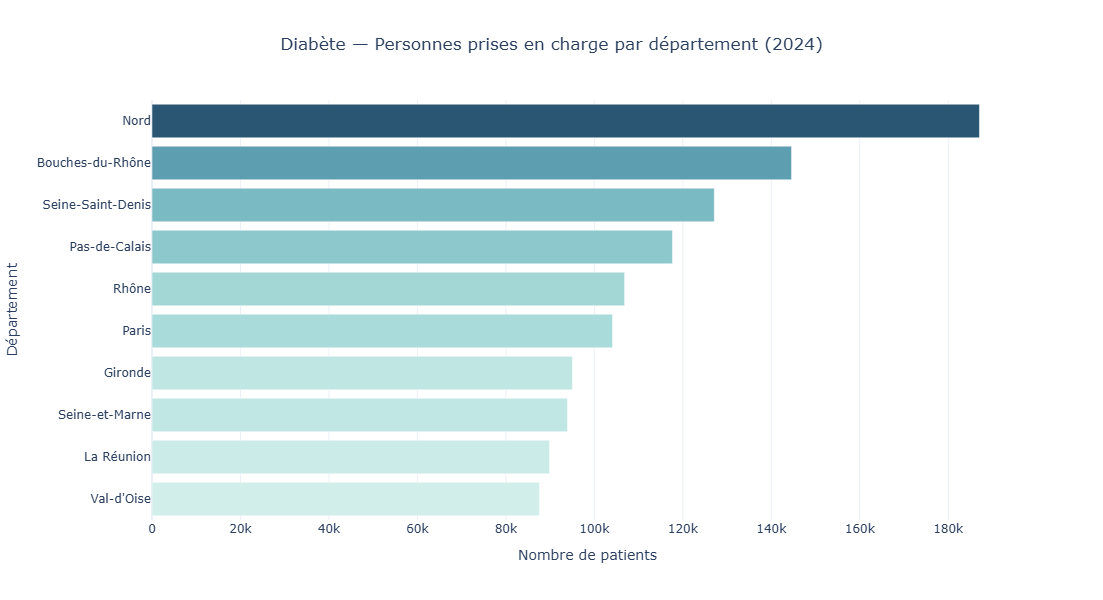

In [35]:
#Construire le graphique

fig = px.bar(
    top10,
    x="effectif_num",
    y="nom_departement",
    orientation="h",
    color="effectif_num",
    color_continuous_scale="Teal",
    hover_data=["code_dept", "code_region_insee"],
    title="Diabète — Personnes prises en charge par département (2024)",
    labels={
        "effectif_num": "Nombre de patients",
        "nom_departement": "Département"
    },
    template="plotly_white"
)

fig.update_layout(
    height=600,
    title_x=0.5,
    coloraxis_showscale=False
)

fig.show()

## 6. Exporter les données

In [36]:
#Sauvegarder le DataFrame
sortie_csv = PROCESSED / "healthpulse_diabete_dept_2024_j04.csv"

df_joint.to_csv(
    sortie_csv,
    index=False,
    encoding="utf-8-sig"
)

In [37]:
#Exporter le graphique interactif en HTML

dossier_figures = RACINE / "outputs" / "figures"
dossier_figures.mkdir(parents=True, exist_ok=True)

fig.write_html(
    dossier_figures / "j04_top10_diabete.html"
)

In [39]:
#Controles finaux

assert len(df_joint) == len(df_cnam)

assert df_joint["code_dept"].notna().all()

assert df_joint["nom_departement"].notna().all()

print("Contrôles finaux réussis.")

Contrôles finaux réussis.
